Assignment 5 : Implement and compare RNN, LSTM, GRU Model for sequence classification and analyze their performance using appropriate evaluation metrics

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

# Load IMDB dataset
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Pad sequences to equal length
X_train = pad_sequences(
    X_train, maxlen=max_length, padding="post"
)
X_test = pad_sequences(
    X_test, maxlen=max_length, padding="post"
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input shape:", X_train.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training samples: 25000
Testing samples: 25000
Input shape: (25000, 200)


In [ ]:
# Define model architectures
def build_model(model_type):
    model = Sequential()
    model.add(Embedding(input_dim=10000, output_dim=64))

    if model_type == "RNN":
        model.add(SimpleRNN(64))
    elif model_type == "LSTM":
        model.add(LSTM(64))
    elif model_type == "GRU":
        model.add(GRU(64))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Train and evaluate models
results = []
models = {}

for model_type in ["RNN", "LSTM", "GRU"]:
    print(f"\nTraining {model_type} model...")

    model = build_model(model_type)

    start_time = time.time()

    model.fit(
        X_train, y_train,
        epochs=3,
        batch_size=128,
        validation_split=0.2,
        verbose=1
    )

    training_time = time.time() - start_time

    y_prob = model.predict(X_test, verbose=0)
    y_pred = (y_prob >= 0.5).astype(int).flatten()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": model_type,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Training Time (s)": training_time
    })

    models[model_type] = model

    print(f"{model_type} Test Accuracy: {accuracy:.4f}")
    print(f"{model_type} Training Time: {training_time:.2f} seconds")


Training RNN model...
Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 28s 129ms/step - accuracy: 0.5278 - loss: 0.6894 - val_accuracy: 0.5424 - val_loss: 0.6804
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 149ms/step - accuracy: 0.6081 - loss: 0.6298 - val_accuracy: 0.5518 - val_loss: 0.7011
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 38s 129ms/step - accuracy: 0.6988 - loss: 0.5075 - val_accuracy: 0.5390 - val_loss: 0.7132
RNN Test Accuracy: 0.5271
RNN Training Time: 89.75 seconds

Training LSTM model...
Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 75s 440ms/step - accuracy: 0.5596 - loss: 0.6731 - val_accuracy: 0.7550 - val_loss: 0.5506
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 360ms/step - accuracy: 0.6742 - loss: 0.6017 - val_accuracy: 0.6496 - val_loss: 0.6263
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 359ms/step - accuracy: 0.7401 - loss: 0.5428 - val_accuracy: 0.7878 - val_loss: 0.5319
LSTM Test Accuracy: 0.7943
LSTM Training Time: 187.92 seconds

Training GRU model...
Epoch 1/3
157/157 ━━━━━━━━━━━

In [ ]:
results_df = pd.DataFrame(results)

print("\nPerformance Comparison:")
print(results_df.round(4).to_string(index=False))


Performance Comparison:
Model  Accuracy  Precision  Recall  F1-Score  Training Time (s)
  RNN    0.5271     0.5520  0.2874    0.3780            89.7495
 LSTM    0.7943     0.8230  0.7498    0.7847           187.9161
  GRU    0.8215     0.7893  0.8772    0.8309           184.8555


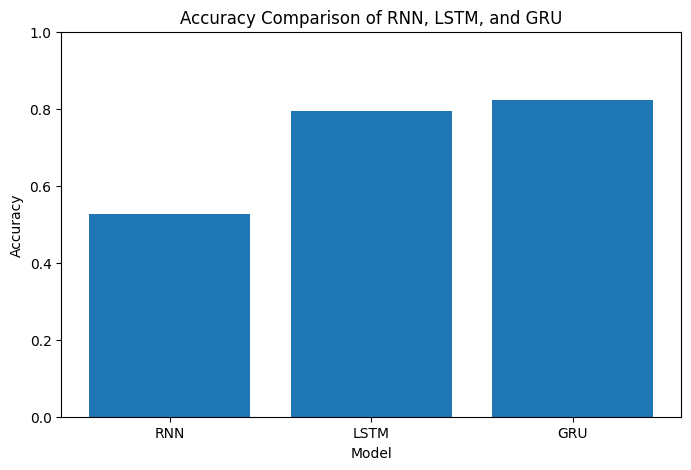

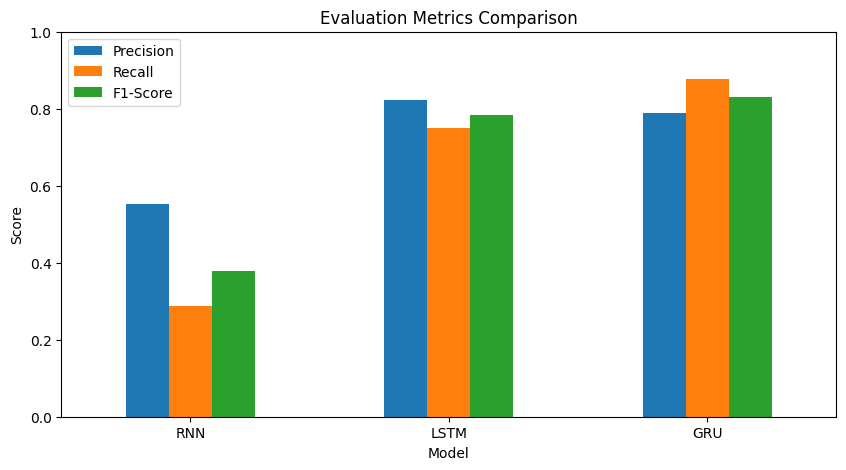

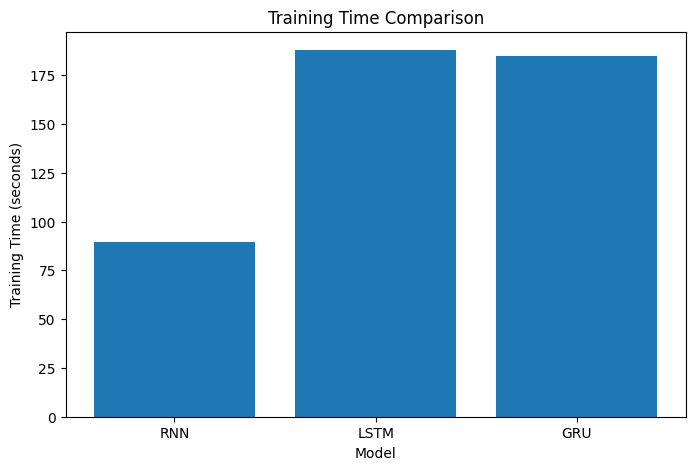

In [ ]:
# Accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.title("Accuracy Comparison of RNN, LSTM, and GRU")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# Precision, Recall, and F1-score comparison
results_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Evaluation Metrics Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# Training time comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Training Time (s)"])
plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.show()